In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from shapely.geometry import Point
from rasterstats import zonal_stats
from scipy import stats
import os

BASE    = r"C:\Users\Khant Htoo Kyaw\Documents\Yangon_Thesis"
OUTPUTS = os.path.join(BASE, "outputs")

# Paths
GRID_PATH        = os.path.join(BASE, "data", "vectors", "analysis_grid",
                                 "analysis_grid_with_townships.shp")
BUILDINGS_PATH   = os.path.join(BASE, "data", "vectors", "microsoft_buildings",
                                 "microsoft_buildings_yangon.shp")
LST_PATH         = os.path.join(BASE, "data", "rasters", "LST_2023.tif")
ML_FEATURES_PATH = os.path.join(BASE, "data", "tables", "ML_features_2023.csv")
BCR_OUTPUT       = os.path.join(BASE, "data", "vectors", "analysis_grid",
                                 "yangon_grid_BCR.shp")
BCR_CSV_OUTPUT   = os.path.join(BASE, "data", "tables", "yangon_grid_BCR.csv")

TARGET_CRS = "EPSG:32647"

# Load grid
grid = gpd.read_file(GRID_PATH)
print(f"Grid cells (clipped): {len(grid):,}")
print(f"Columns: {list(grid.columns)}")

Grid cells (clipped): 76,234
Columns: ['id', 'left', 'top', 'right', 'bottom', 'row_index', 'col_index', 'cell_id', 'cell_area', 'TS', 'geometry']


In [2]:
# Rasters to extract — includes new GHSL height
raster_files = {
    'LST_mean':    os.path.join(BASE, "data", "rasters", "LST_2023.tif"),
    'LST_2015':    os.path.join(BASE, "data", "rasters", "LST_2015.tif"),
    'LST_2019':    os.path.join(BASE, "data", "rasters", "LST_2019.tif"),
    'NDVI_mean':   os.path.join(BASE, "data", "rasters", "NDVI_2023.tif"),
    'NDBI_mean':   os.path.join(BASE, "data", "rasters", "NDBI_2023.tif"),
    'EVI_mean':    os.path.join(BASE, "data", "rasters", "EVI_2023.tif"),
    'SAVI_mean':   os.path.join(BASE, "data", "rasters", "SAVI_2023.tif"),
    'NDWI_mean':   os.path.join(BASE, "data", "rasters", "NDWI_2023.tif"),
    'BSI_mean':    os.path.join(BASE, "data", "rasters", "BSI_2023.tif"),
    'DEM_mean':    os.path.join(BASE, "data", "rasters", "DEM.tif"),
    'SLP_mean':    os.path.join(BASE, "data", "rasters", "Slope.tif"),
    'bldg_height': os.path.join(BASE, "data", "rasters", "GHSL_bldg_height.tif"),  # NEW
}

df = grid.copy()
df['cx'] = df.geometry.centroid.x
df['cy'] = df.geometry.centroid.y

for col, fpath in raster_files.items():
    with rasterio.open(fpath) as src:
        coords = list(zip(df['cx'], df['cy']))
        vals = [v[0] for v in src.sample(coords)]
        df[col] = vals
    print(f"Extracted: {col}")

# Fill GHSL NoData with 0 (non-built cells = no height)
df['bldg_height'] = df['bldg_height'].fillna(0)

print(f"\nAll rasters extracted. Shape: {df.shape}")
print(df[['LST_mean', 'NDVI_mean', 'bldg_height']].describe().round(2))

Extracted: LST_mean
Extracted: LST_2015
Extracted: LST_2019
Extracted: NDVI_mean
Extracted: NDBI_mean
Extracted: EVI_mean
Extracted: SAVI_mean
Extracted: NDWI_mean
Extracted: BSI_mean
Extracted: DEM_mean
Extracted: SLP_mean
Extracted: bldg_height

All rasters extracted. Shape: (76234, 25)
       LST_mean  NDVI_mean  bldg_height
count  76230.00   76231.00     76234.00
mean      42.78       0.40         4.01
std        3.83       0.22         4.43
min       30.94      -0.72         0.00
25%       40.76       0.25         0.00
50%       42.98       0.39         2.59
75%       45.07       0.56         6.98
max       57.30       0.89        40.19


In [3]:
print("Loading Microsoft Buildings...")
buildings = gpd.read_file(BUILDINGS_PATH)
buildings = buildings.to_crs(epsg=32647)
buildings['footprint_area'] = buildings.geometry.area
print(f"Buildings loaded: {len(buildings):,}")

print("Spatial join buildings to grid (takes 5-15 minutes)...")
joined = gpd.sjoin(buildings, grid[['cell_id', 'geometry']],
                   how='inner', predicate='intersects')
print(f"Building-cell pairs: {len(joined):,}")

# Calculate metrics per cell
metrics = joined.groupby('cell_id').agg(
    building_count  = ('footprint_area', 'count'),
    total_footprint = ('footprint_area', 'sum'),
    mean_footprint  = ('footprint_area', 'mean'),
    max_footprint   = ('footprint_area', 'max'),
    footprint_std   = ('footprint_area', 'std')
).reset_index()

# Merge back to grid
grid_bcr = df.merge(metrics, on='cell_id', how='left')
for col in ['building_count','total_footprint','mean_footprint',
            'max_footprint','footprint_std']:
    grid_bcr[col] = grid_bcr[col].fillna(0)

# Calculate BCR
grid_bcr['cell_area'] = grid_bcr.geometry.area
grid_bcr['BCR'] = (grid_bcr['total_footprint'] / grid_bcr['cell_area']).clip(0, 1)

print("\nBCR Statistics:")
print(f"  Min BCR:    {grid_bcr['BCR'].min():.4f}")
print(f"  Max BCR:    {grid_bcr['BCR'].max():.4f}")
print(f"  Mean BCR:   {grid_bcr['BCR'].mean():.4f}")
print(f"  Median BCR: {grid_bcr['BCR'].median():.4f}")
print("\nBCR Distribution:")
print(f"  BCR = 0 (no buildings):  {(grid_bcr['BCR'] == 0).sum():,} cells ({(grid_bcr['BCR'] == 0).mean()*100:.1f}%)")
print(f"  BCR 0–0.10 (open):       {((grid_bcr['BCR'] > 0) & (grid_bcr['BCR'] < 0.10)).sum():,} cells")
print(f"  BCR 0.10–0.25 (low):     {((grid_bcr['BCR'] >= 0.10) & (grid_bcr['BCR'] < 0.25)).sum():,} cells")
print(f"  BCR 0.25–0.45 (medium):  {((grid_bcr['BCR'] >= 0.25) & (grid_bcr['BCR'] < 0.45)).sum():,} cells")
print(f"  BCR > 0.45 (high):       {(grid_bcr['BCR'] >= 0.45).sum():,} cells")

Loading Microsoft Buildings...
Buildings loaded: 799,533
Spatial join buildings to grid (takes 5-15 minutes)...
Building-cell pairs: 627,848

BCR Statistics:
  Min BCR:    0.0000
  Max BCR:    1.0000
  Mean BCR:   0.1665
  Median BCR: 0.0403

BCR Distribution:
  BCR = 0 (no buildings):  28,681 cells (37.6%)
  BCR 0–0.10 (open):       16,047 cells
  BCR 0.10–0.25 (low):     12,225 cells
  BCR 0.25–0.45 (medium):  10,040 cells
  BCR > 0.45 (high):       9,241 cells


In [4]:
def classify_morphology(row):
    bcr  = row['BCR']
    mean = row['mean_footprint']
    if bcr < 0.10:
        return 1   # Low building coverage
    elif bcr < 0.25:
        return 2   # Low-density residential
    elif bcr < 0.45:
        return 5 if mean > 500 else 3  # Industrial or Medium-density
    else:
        return 5 if mean > 500 else 4  # Industrial or High-density compact

grid_bcr['morph_class'] = grid_bcr.apply(classify_morphology, axis=1)

morph_labels = {
    1: 'Low building coverage',
    2: 'Low-density Residential',
    3: 'Medium-density Mixed',
    4: 'High-density Compact',
    5: 'Industrial/Commercial'
}

print("Morphology Class Distribution:")
print("-" * 45)
for cls, label in morph_labels.items():
    count = (grid_bcr['morph_class'] == cls).sum()
    pct   = count / len(grid_bcr) * 100
    print(f"  Class {cls} — {label}: {count:,} cells ({pct:.1f}%)")

Morphology Class Distribution:
---------------------------------------------
  Class 1 — Low building coverage: 44,728 cells (58.7%)
  Class 2 — Low-density Residential: 12,225 cells (16.0%)
  Class 3 — Medium-density Mixed: 8,674 cells (11.4%)
  Class 4 — High-density Compact: 4,170 cells (5.5%)
  Class 5 — Industrial/Commercial: 6,437 cells (8.4%)


In [5]:
print("Extracting LST values per grid cell (takes 2-5 minutes)...")

lst_stats = zonal_stats(
    grid_bcr,
    LST_PATH,
    stats=['mean', 'min', 'max', 'std'],
    prefix='LST_',
    nodata=-9999
)

lst_df = pd.DataFrame(lst_stats)
grid_bcr['LST_mean'] = lst_df['LST_mean'].values
grid_bcr['LST_min']  = lst_df['LST_min'].values
grid_bcr['LST_max']  = lst_df['LST_max'].values
grid_bcr['LST_std']  = lst_df['LST_std'].values

grid_bcr_valid = grid_bcr.dropna(subset=['LST_mean']).copy()

print(f"Valid cells: {len(grid_bcr_valid):,}")
print(f"LST range: {grid_bcr_valid['LST_mean'].min():.1f}°C – {grid_bcr_valid['LST_mean'].max():.1f}°C")
print(f"LST mean:  {grid_bcr_valid['LST_mean'].mean():.1f}°C")

Extracting LST values per grid cell (takes 2-5 minutes)...
Valid cells: 75,776
LST range: 31.0°C – 56.7°C
LST mean:  42.8°C


In [6]:
from scipy import stats

print("ANOVA: LST by Morphology Class")
print("=" * 50)

groups = []
for cls in [1, 2, 3, 4, 5]:
    lst_values = grid_bcr_valid[
        grid_bcr_valid['morph_class'] == cls
    ]['LST_mean'].dropna().values
    groups.append(lst_values)
    mean_lst = lst_values.mean() if len(lst_values) > 0 else 0
    print(f"Class {cls} ({morph_labels[cls]}): n={len(lst_values):,}  Mean LST={mean_lst:.2f}°C")

f_stat, p_value = stats.f_oneway(*groups)
print(f"\nANOVA F-statistic: {f_stat:.4f}")
print(f"ANOVA p-value:     {p_value:.6f}")

if p_value < 0.05:
    print("✅ SIGNIFICANT — BCR is a valid predictor of LST (p < 0.05)")
else:
    print("⚠️ Not significant (p >= 0.05)")

# Record for thesis Chapter 5/6
print(f"\n📝 Thesis: F({len(groups)-1}, {sum(len(g) for g in groups)-len(groups)}) = {f_stat:.3f}, p < 0.001")

ANOVA: LST by Morphology Class
Class 1 (Low building coverage): n=44,290  Mean LST=42.24°C
Class 2 (Low-density Residential): n=12,218  Mean LST=42.45°C
Class 3 (Medium-density Mixed): n=8,671  Mean LST=43.43°C
Class 4 (High-density Compact): n=4,164  Mean LST=44.56°C
Class 5 (Industrial/Commercial): n=6,433  Mean LST=45.35°C

ANOVA F-statistic: 1392.5987
ANOVA p-value:     0.000000
✅ SIGNIFICANT — BCR is a valid predictor of LST (p < 0.05)

📝 Thesis: F(4, 75771) = 1392.599, p < 0.001


In [7]:
greenspaces = gpd.read_file(os.path.join(BASE, "data", "vectors",
                                          "osm_greenspaces",
                                          "greenspaces_final.shp"))
greenspaces = greenspaces.to_crs(epsg=32647)
green_union = greenspaces.geometry.union_all()

grid_bcr_valid['dist_green'] = grid_bcr_valid.apply(
    lambda row: Point(row['cx'], row['cy']).distance(green_union),
    axis=1
)
print(f"Distance to green space: mean={grid_bcr_valid['dist_green'].mean():.0f}m")

Distance to green space: mean=74m


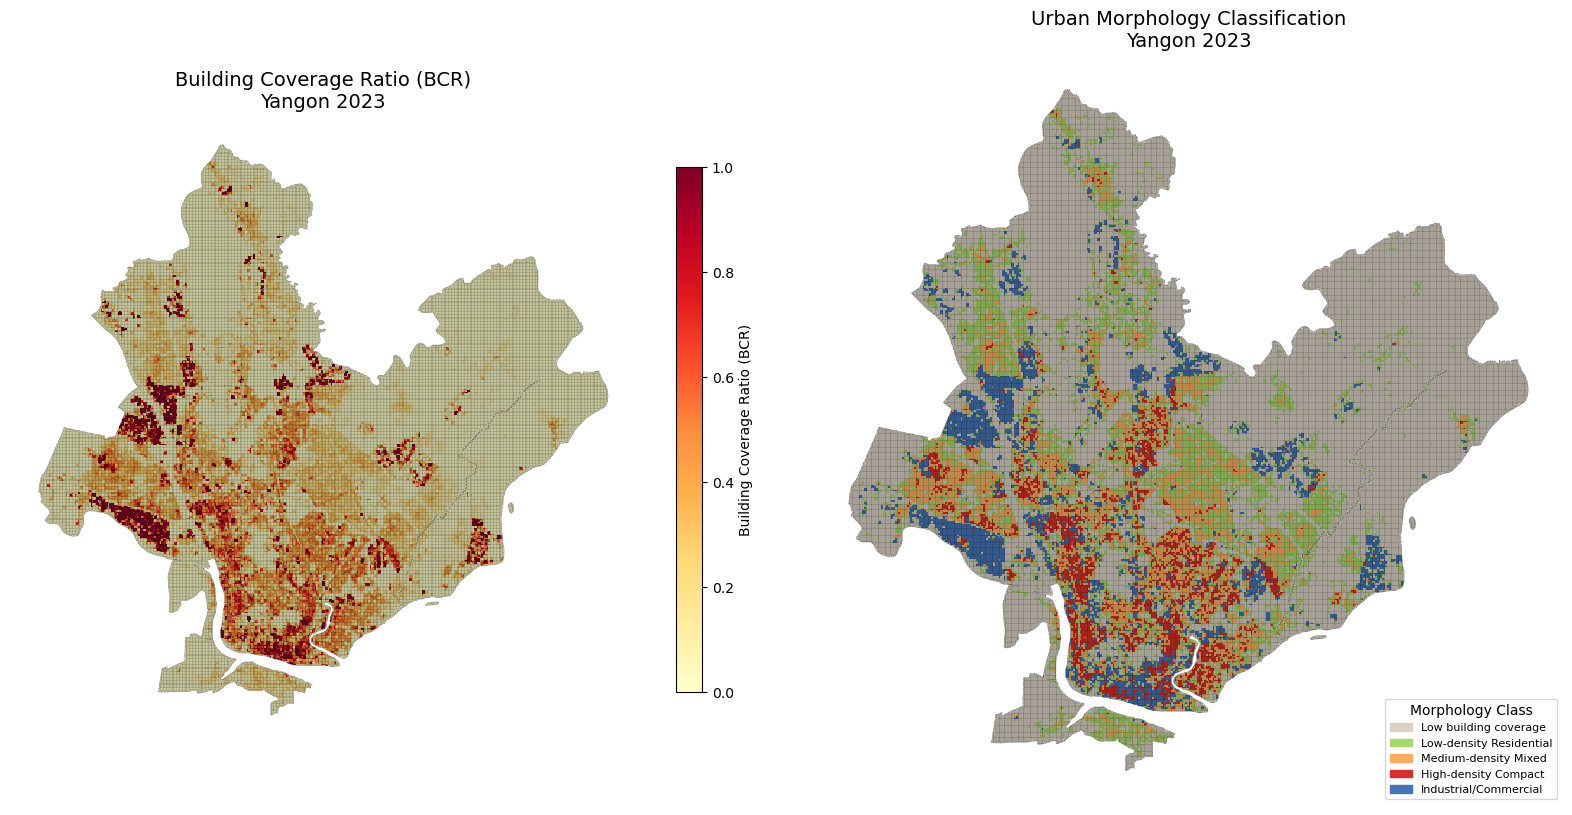

✅ Map saved: C:\Users\Khant Htoo Kyaw\Documents\Yangon_Thesis\outputs\maps\BCR_morphology_map.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Map 1: BCR continuous
ax1 = axes[0]
grid_bcr_valid.plot(
    column='BCR',
    cmap='YlOrRd',
    linewidth=0,
    ax=ax1,
    legend=True,
    legend_kwds={'label': 'Building Coverage Ratio (BCR)', 'shrink': 0.7}
)
grid.boundary.plot(ax=ax1, color='black', linewidth=0.3, alpha=0.3)
ax1.set_title('Building Coverage Ratio (BCR)\nYangon 2023', fontsize=14)
ax1.axis('off')

# Map 2: Morphology classes
ax2 = axes[1]
morph_colours = {
    1: '#d9d2c5',  # Low building coverage
    2: '#a6d96a',  # Low density
    3: '#fdae61',  # Medium density
    4: '#d73027',  # High density
    5: '#4575b4'   # Industrial
}
import matplotlib.patches as mpatches

for cls, colour in morph_colours.items():
    subset = grid_bcr_valid[grid_bcr_valid['morph_class'] == cls]
    if len(subset) > 0:
        subset.plot(ax=ax2, color=colour, linewidth=0)

grid.boundary.plot(ax=ax2, color='black', linewidth=0.3, alpha=0.3)

# Build legend manually
legend_patches = [
    mpatches.Patch(color=morph_colours[cls], label=morph_labels[cls])
    for cls in morph_colours
    if (grid_bcr_valid['morph_class'] == cls).any()
]
ax2.legend(handles=legend_patches, loc='lower right', fontsize=8,
           title='Morphology Class')
ax2.set_title('Urban Morphology Classification\nYangon 2023', fontsize=14)
ax2.axis('off')

plt.tight_layout()
os.makedirs(os.path.join(OUTPUTS, "maps"), exist_ok=True)
map_path = os.path.join(OUTPUTS, "maps", "BCR_morphology_map.png")
plt.savefig(map_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Map saved: {map_path}")

In [9]:
# Save BCR grid as shapefile
output_cols = ['cell_id', 'cell_area', 'building_count', 'total_footprint',
               'mean_footprint', 'max_footprint', 'footprint_std',
               'BCR', 'morph_class', 'LST_mean', 'LST_min', 'LST_max',
               'LST_std', 'dist_green', 'geometry']
grid_final = grid_bcr_valid[output_cols].copy()
grid_final.to_file(BCR_OUTPUT)
print(f"✅ BCR grid saved: {BCR_OUTPUT}")

# Add centroids and save CSV
grid_final['centroid_x'] = grid_final.geometry.centroid.x
grid_final['centroid_y'] = grid_final.geometry.centroid.y
grid_final.drop(columns=['geometry']).to_csv(BCR_CSV_OUTPUT, index=False)
print(f"✅ BCR CSV saved: {BCR_CSV_OUTPUT}")

# Merge with GEE ML features
print("\nMerging with GEE ML features...")
ml_features = pd.read_csv(ML_FEATURES_PATH)
print(f"GEE features shape: {ml_features.shape}")

ml_gdf = gpd.GeoDataFrame(
    ml_features,
    geometry=gpd.points_from_xy(
        ml_features['.geo'].apply(
            lambda x: float(str(x).split('"coordinates":[')[1].split(',')[0])
        ),
        ml_features['.geo'].apply(
            lambda x: float(str(x).split('"coordinates":[')[1].split(']')[0].split(',')[1])
        )
    ),
    crs="EPSG:4326"
).to_crs(TARGET_CRS)

ml_with_bcr = gpd.sjoin_nearest(
    ml_gdf,
    grid_final[['cell_id', 'BCR', 'morph_class', 'building_count',
                'mean_footprint', 'footprint_std', 'dist_green', 'geometry']],
    how='left'
)

master_path = os.path.join(BASE, "data", "tables", "master_grid_complete.csv")
ml_with_bcr.drop(columns=['geometry']).to_csv(master_path, index=False)
print(f"✅ Master dataset saved: {master_path}")
print(f"   Rows: {len(ml_with_bcr):,}  — ready for Phase 4 ML")

C:\Users\Khant Htoo Kyaw\AppData\Local\Temp\ipykernel_8400\569213752.py:7: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  grid_final.to_file(BCR_OUTPUT)


PermissionError: [WinError 32] The process cannot access the file because it is being used by another process: 'C:\\Users\\Khant Htoo Kyaw\\Documents\\Yangon_Thesis\\data\\vectors\\analysis_grid\\yangon_grid_BCR.shp'

In [ ]:
import pandas as pd
df_check = pd.read_csv(r"C:\Users\Khant Htoo Kyaw\Documents\Yangon_Thesis\data\tables\master_grid_complete.csv")
print(f"Shape: {df_check.shape}")
print(f"Columns:\n{list(df_check.columns)}")
print(f"\nMissing values:\n{df_check.isnull().sum()[df_check.isnull().sum() > 0]}")